# Red Neuronal Convolucional (CNN) para clasificación de prendas — Fashion-MNIST

**Objetivo:** construir, entrenar y evaluar una CNN con Keras/TensorFlow que clasifique imágenes de prendas de vestir y calzado en 10 categorías, usando *Data Augmentation* y *EarlyStopping*. El modelo entrenado se guarda en `models/fashion_mnist_cnn.keras` y se consume desde una aplicación Streamlit (`app.py`).

**Contenido del notebook**
1. Instalación / configuración (compatible con Google Colab)
2. Selección y descripción del dataset
3. Exploración y visualización de imágenes
4. Preprocesamiento, normalización y división entrenamiento / validación / prueba
5. Data Augmentation
6. Construcción de la CNN
7. Entrenamiento con EarlyStopping
8. Gráficas de entrenamiento (loss / accuracy)
9. Evaluación: accuracy, precision, recall, F1, `classification_report`, matriz de confusión
10. Visualización de predicciones (≥ 10 imágenes)
11. Guardado del modelo
12. Conclusiones

## 1. Instalación y configuración

La siguiente celda detecta si se ejecuta en **Google Colab**. En Colab, TensorFlow, scikit-learn, matplotlib y seaborn ya vienen instalados, por lo que solo se verifica su presencia. El dataset se descarga automáticamente desde `keras.datasets` (servidores públicos de Google), **sin necesidad de autenticación** ni de Google Drive.

> En local, instala primero las dependencias con `pip install -r requirements.txt` dentro de un entorno virtual.

In [1]:
import sys, subprocess, importlib.util

EN_COLAB = "google.colab" in sys.modules
print("¿Ejecutando en Google Colab?", EN_COLAB)

# Instala solo lo que falte (en Colab normalmente no se instala nada)
paquetes = {"tensorflow": "tensorflow", "sklearn": "scikit-learn", "matplotlib": "matplotlib",
            "seaborn": "seaborn", "pandas": "pandas", "PIL": "pillow"}
faltantes = [pip for mod, pip in paquetes.items() if importlib.util.find_spec(mod) is None]
if faltantes:
    print("Instalando:", faltantes)
    subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", *faltantes])
else:
    print("Todas las dependencias están disponibles.")

¿Ejecutando en Google Colab? False
Todas las dependencias están disponibles.


In [2]:
import os
os.environ["TF_CPP_MIN_LOG_LEVEL"] = "2"

import json
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers
from sklearn.model_selection import train_test_split
from sklearn.metrics import (accuracy_score, precision_recall_fscore_support,
                             classification_report, confusion_matrix)

SEED = 42
keras.utils.set_random_seed(SEED)   # fija semillas de Python, NumPy y TensorFlow

plt.rcParams["figure.dpi"] = 100
sns.set_theme(style="whitegrid")

# Carpetas de salida: en local (notebooks/) se usa la raíz del repositorio; en Colab, el directorio actual
RAIZ = Path("..") if Path("../src").exists() else Path(".")
MODELS_DIR = RAIZ / "models"; MODELS_DIR.mkdir(exist_ok=True)
REPORTS_DIR = RAIZ / "reports"; REPORTS_DIR.mkdir(exist_ok=True)

print("TensorFlow:", tf.__version__)
print("Dispositivos:", [d.device_type for d in tf.config.list_physical_devices()])
print("Raíz del proyecto:", RAIZ.resolve())

TensorFlow: 2.21.0
Dispositivos: ['CPU']
Raíz del proyecto: /Users/jaimecladeron/Desktop/uninpahu/cnn-streamlit


## 2. Selección y descripción del dataset

Se eligió **Fashion-MNIST** (Zalando Research, 2017), disponible en `keras.datasets.fashion_mnist`.

| Característica | Valor |
|---|---|
| Imágenes de entrenamiento | 60.000 |
| Imágenes de prueba | 10.000 |
| Tamaño | 28 × 28 píxeles, escala de grises (1 canal) |
| Valores de píxel | enteros 0–255 |
| Clases | 10, balanceadas (6.000 por clase en entrenamiento) |

**Clases:** 0 Camiseta/top · 1 Pantalón · 2 Suéter · 3 Vestido · 4 Abrigo · 5 Sandalia · 6 Camisa · 7 Zapatilla deportiva · 8 Bolso · 9 Botín.

**¿Por qué Fashion-MNIST y no CIFAR-10?** Ambos son adecuados para CNN, pero Fashion-MNIST (imágenes de 28×28×1) entrena en pocos minutos en CPU / Apple Silicon sin GPU, y aun así es un problema no trivial: varias clases (camisa, camiseta, suéter, abrigo) son visualmente muy parecidas, lo que permite analizar errores de forma interesante. CIFAR-10 (32×32×3, objetos naturales) requeriría redes más profundas y mucho más tiempo de entrenamiento en CPU para lograr resultados comparables.

In [3]:
(x_train_full, y_train_full), (x_test, y_test) = keras.datasets.fashion_mnist.load_data()

CLASS_NAMES = ["Camiseta/top", "Pantalón", "Suéter", "Vestido", "Abrigo",
               "Sandalia", "Camisa", "Zapatilla deportiva", "Bolso", "Botín"]
NUM_CLASSES = len(CLASS_NAMES)

print("x_train_full:", x_train_full.shape, x_train_full.dtype)
print("y_train_full:", y_train_full.shape, y_train_full.dtype)
print("x_test:      ", x_test.shape)
print("y_test:      ", y_test.shape)
print("Rango de píxeles:", x_train_full.min(), "-", x_train_full.max())

x_train_full: (60000, 28, 28) uint8
y_train_full: (60000,) uint8
x_test:       (10000, 28, 28)
y_test:       (10000,)
Rango de píxeles: 0 - 255


## 3. Exploración y visualización de imágenes

### 3.1 Distribución de clases

,Clase,Entrenamiento,Prueba
0,Camiseta/top,6000,1000
1,Pantalón,6000,1000
2,Suéter,6000,1000
3,Vestido,6000,1000
4,Abrigo,6000,1000
5,Sandalia,6000,1000
6,Camisa,6000,1000
7,Zapatilla deportiva,6000,1000
8,Bolso,6000,1000
9,Botín,6000,1000


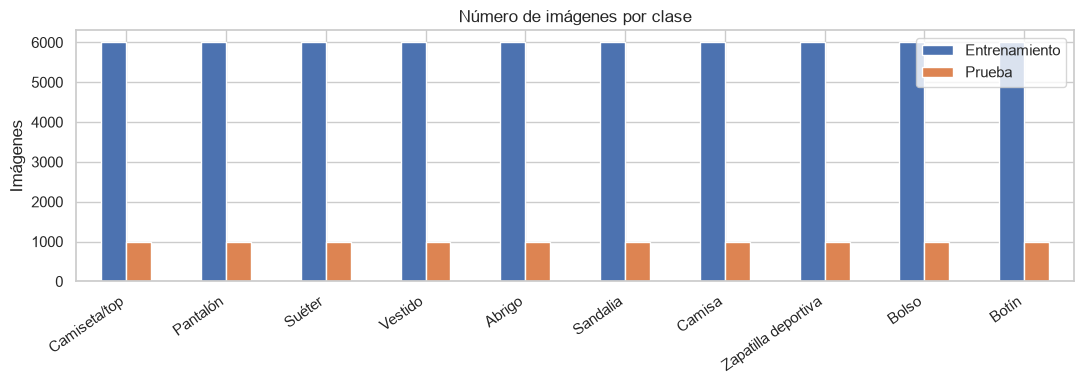

In [4]:
dist = pd.DataFrame({
    "Clase": CLASS_NAMES,
    "Entrenamiento": np.bincount(y_train_full, minlength=NUM_CLASSES),
    "Prueba": np.bincount(y_test, minlength=NUM_CLASSES),
})
display(dist)

ax = dist.set_index("Clase").plot(kind="bar", figsize=(11, 4), color=["#4C72B0", "#DD8452"])
ax.set_title("Número de imágenes por clase"); ax.set_ylabel("Imágenes"); ax.set_xlabel("")
plt.xticks(rotation=35, ha="right"); plt.tight_layout(); plt.show()

El dataset está **perfectamente balanceado** (6.000 imágenes por clase en entrenamiento y 1.000 en prueba), por lo que *accuracy* es una métrica representativa; aun así se reportan precision, recall y F1 por clase.

### 3.2 Muestras aleatorias

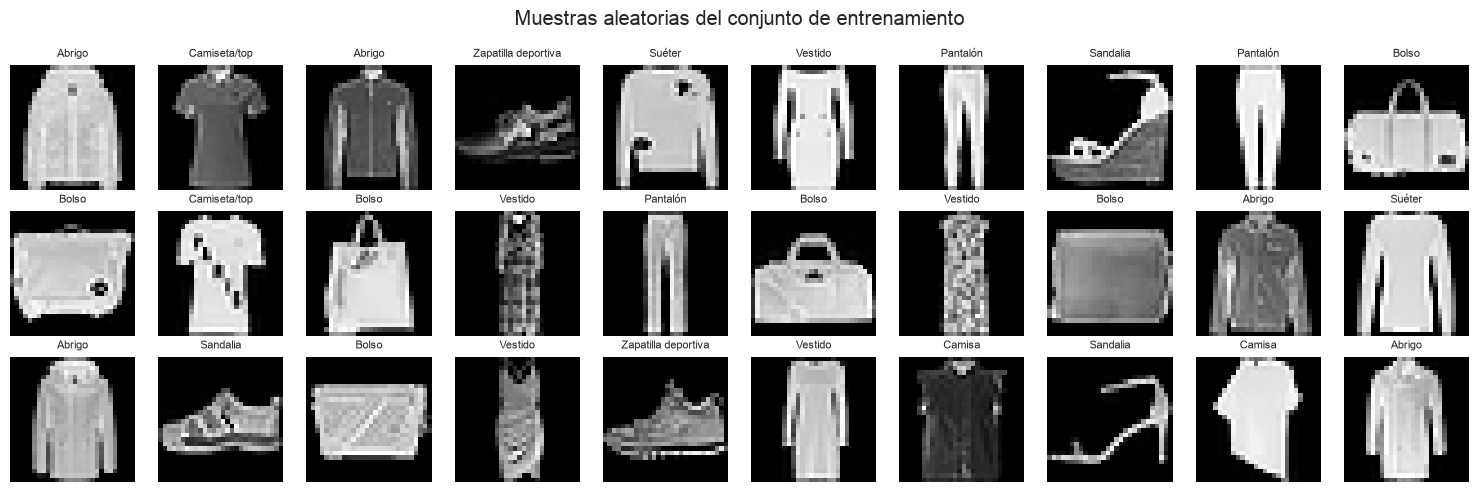

In [5]:
rng = np.random.default_rng(SEED)
idx = rng.choice(len(x_train_full), 30, replace=False)
fig, axes = plt.subplots(3, 10, figsize=(15, 5))
for ax, i in zip(axes.ravel(), idx):
    ax.imshow(x_train_full[i], cmap="gray")
    ax.set_title(CLASS_NAMES[y_train_full[i]], fontsize=8)
    ax.axis("off")
plt.suptitle("Muestras aleatorias del conjunto de entrenamiento"); plt.tight_layout(); plt.show()

### 3.3 Varios ejemplos por clase

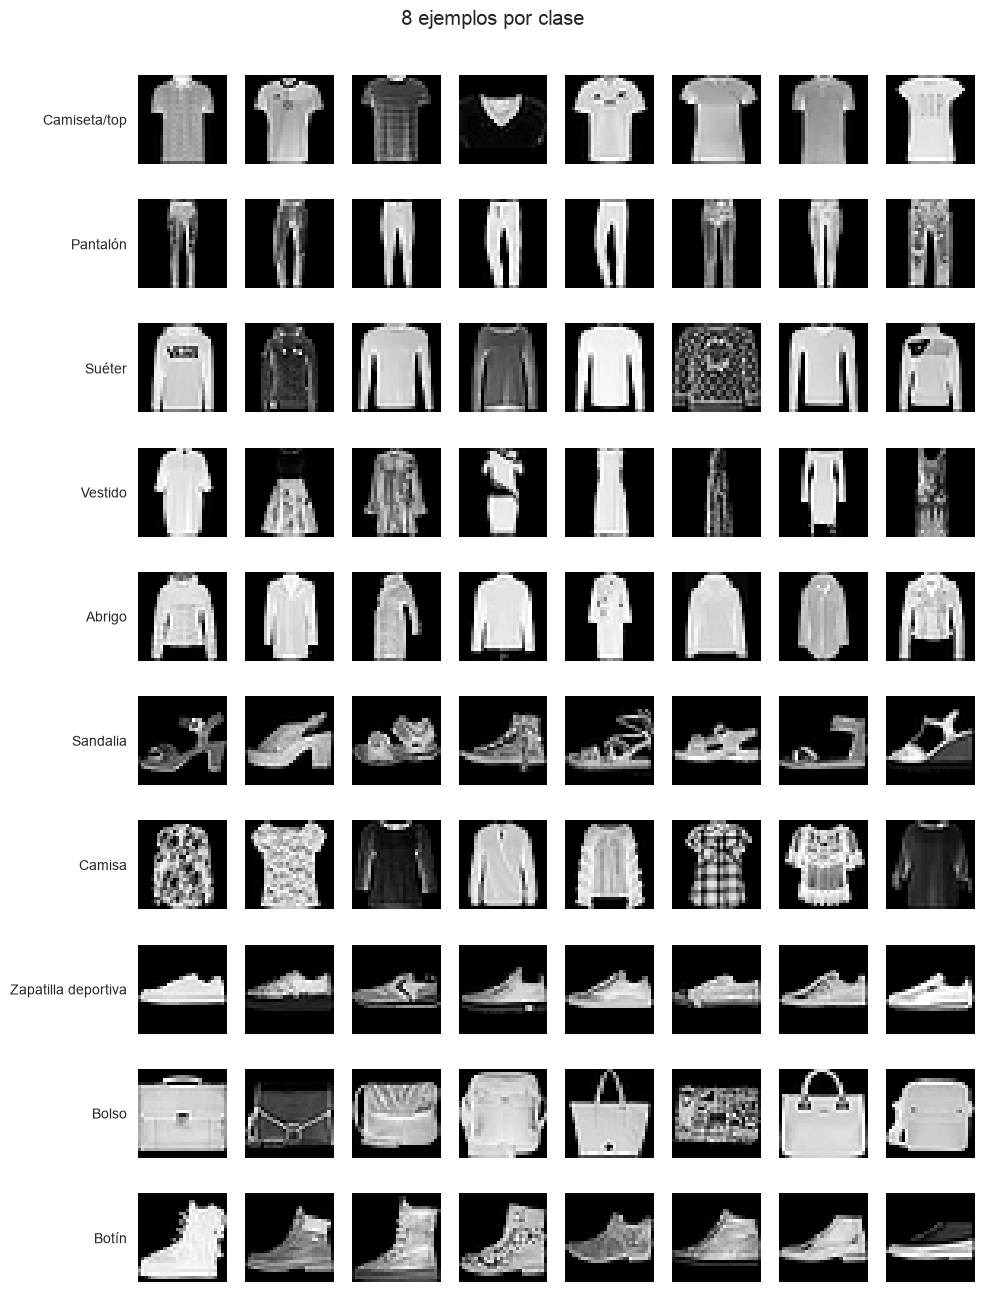

In [6]:
fig, axes = plt.subplots(NUM_CLASSES, 8, figsize=(10, 13))
for c in range(NUM_CLASSES):
    idx_c = rng.choice(np.where(y_train_full == c)[0], 8, replace=False)
    for j, i in enumerate(idx_c):
        ax = axes[c, j]
        ax.imshow(x_train_full[i], cmap="gray"); ax.axis("off")
    axes[c, 0].text(-4, 14, CLASS_NAMES[c], ha="right", va="center", fontsize=10)
plt.suptitle("8 ejemplos por clase", y=1.0); plt.tight_layout(); plt.show()

### 3.4 Imagen promedio por clase e intensidad de píxeles

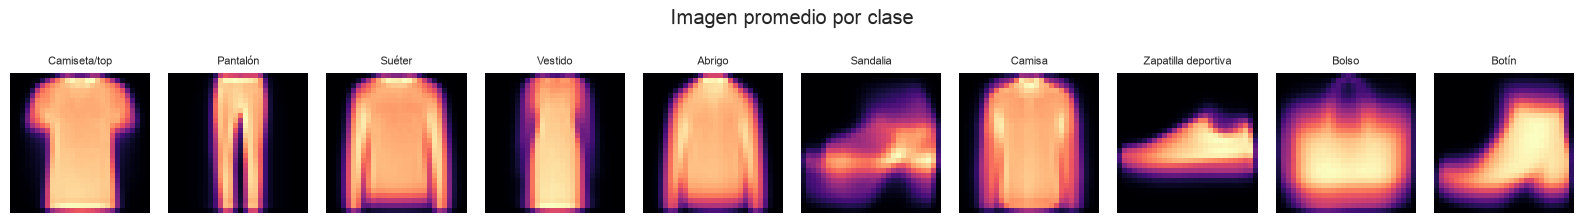

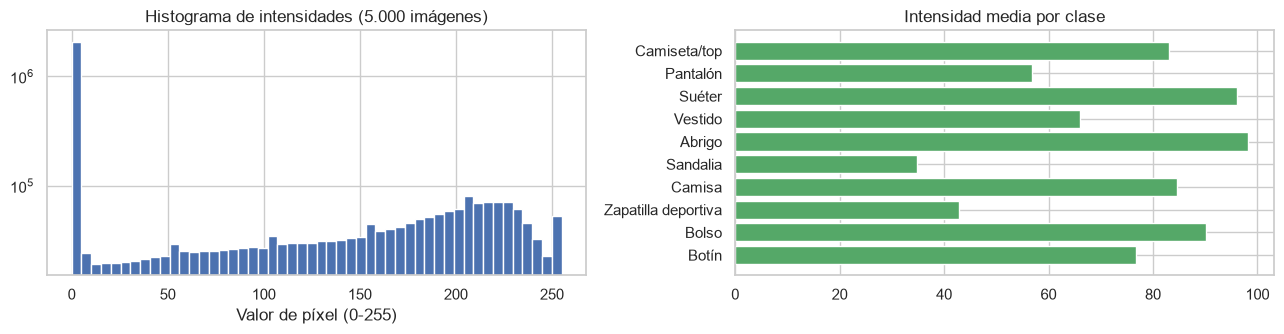

In [7]:
fig, axes = plt.subplots(1, NUM_CLASSES, figsize=(16, 2.4))
for c, ax in enumerate(axes):
    ax.imshow(x_train_full[y_train_full == c].mean(axis=0), cmap="magma")
    ax.set_title(CLASS_NAMES[c], fontsize=8); ax.axis("off")
plt.suptitle("Imagen promedio por clase"); plt.tight_layout(); plt.show()

fig, axes = plt.subplots(1, 2, figsize=(13, 3.5))
axes[0].hist(x_train_full[:5000].ravel(), bins=50, color="#4C72B0")
axes[0].set_title("Histograma de intensidades (5.000 imágenes)"); axes[0].set_yscale("log")
axes[0].set_xlabel("Valor de píxel (0-255)")
medias = [x_train_full[y_train_full == c].mean() for c in range(NUM_CLASSES)]
axes[1].barh(CLASS_NAMES, medias, color="#55A868")
axes[1].set_title("Intensidad media por clase"); axes[1].invert_yaxis()
plt.tight_layout(); plt.show()

**Observaciones de la exploración**
- Las prendas aparecen centradas, en claro sobre fondo negro (la mayoría de píxeles valen 0).
- Las imágenes promedio muestran siluetas muy parecidas entre *Camiseta/top*, *Suéter*, *Abrigo* y *Camisa*: se anticipa que serán las clases más confundidas.
- *Pantalón*, *Bolso*, *Sandalia* y *Botín* tienen formas muy distintivas y deberían clasificarse con facilidad.

## 4. Preprocesamiento, normalización y división de datos

1. **Normalización:** los píxeles (0–255, `uint8`) se convierten a `float32` y se escalan a **[0, 1]** dividiendo entre 255. Esto estabiliza y acelera el entrenamiento por descenso de gradiente.
2. **Canal explícito:** se pasa de `(28, 28)` a `(28, 28, 1)`, formato que esperan las capas `Conv2D`.
3. **División:** las 60.000 imágenes de entrenamiento se dividen de forma **estratificada** en **54.000 para entrenamiento (90 %)** y **6.000 para validación (10 %)**. Las 10.000 de prueba se reservan exclusivamente para la evaluación final.

In [8]:
def preprocesar(x):
    return (x.astype("float32") / 255.0)[..., np.newaxis]

x_train, x_val, y_train, y_val = train_test_split(
    x_train_full, y_train_full, test_size=0.10, stratify=y_train_full, random_state=SEED)

x_train, x_val, x_test_p = preprocesar(x_train), preprocesar(x_val), preprocesar(x_test)

resumen = pd.DataFrame({
    "Conjunto": ["Entrenamiento", "Validación", "Prueba"],
    "Forma": [x_train.shape, x_val.shape, x_test_p.shape],
    "Imágenes": [len(x_train), len(x_val), len(x_test_p)],
    "Min": [x_train.min(), x_val.min(), x_test_p.min()],
    "Max": [x_train.max(), x_val.max(), x_test_p.max()],
    "Media": [x_train.mean(), x_val.mean(), x_test_p.mean()],
})
display(resumen)
print("Imágenes por clase en validación:", np.bincount(y_val))

,Conjunto,Forma,Imágenes,Min,Max,Media
0,Entrenamiento,"(54000, 28, 28, 1)",54000,0.0,1.0,0.286209
1,Validación,"(6000, 28, 28, 1)",6000,0.0,1.0,0.284525
2,Prueba,"(10000, 28, 28, 1)",10000,0.0,1.0,0.286849


Imágenes por clase en validación: [600 600 600 600 600 600 600 600 600 600]


## 5. Data Augmentation

Para mejorar la generalización y reducir el sobreajuste se aplican transformaciones aleatorias **solo durante el entrenamiento**, usando capas de preprocesamiento de Keras integradas en el modelo (se desactivan automáticamente en inferencia):

- `RandomFlip("horizontal")`: las prendas son aproximadamente simétricas.
- `RandomRotation(0.05)`: rotaciones de hasta ±18°.
- `RandomTranslation(0.08, 0.08)`: desplazamientos de hasta ±8 %.
- `RandomZoom(0.08)`: acercamientos/alejamientos leves.

No se usan volteos verticales (un zapato boca abajo no es realista en el dataset).

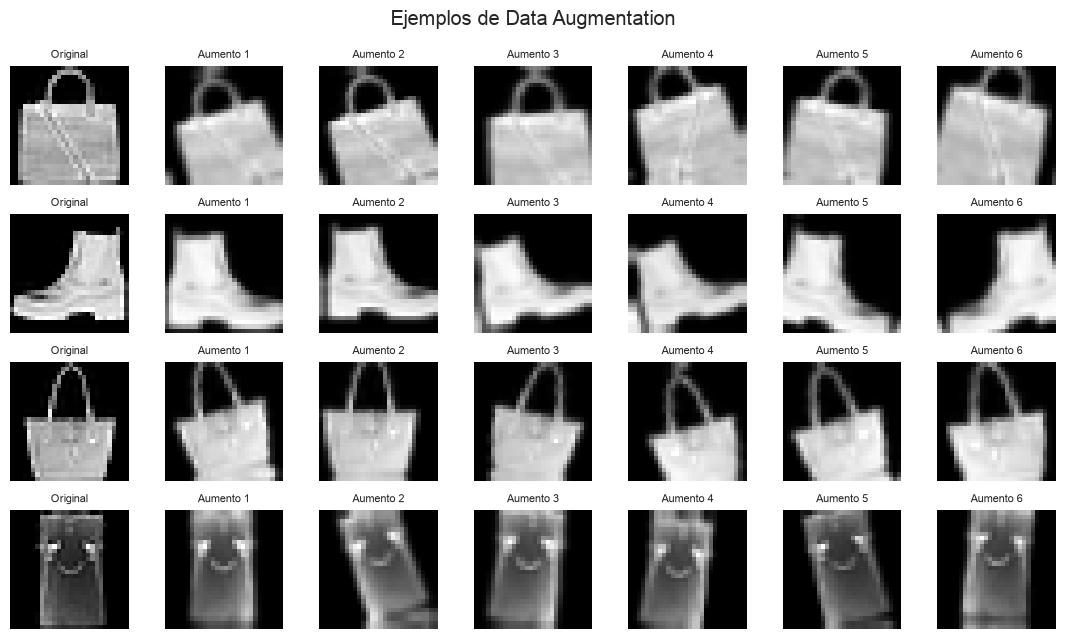

In [9]:
data_augmentation = keras.Sequential([
    layers.RandomFlip("horizontal"),
    layers.RandomRotation(0.05),
    layers.RandomTranslation(0.08, 0.08),
    layers.RandomZoom(0.08),
], name="data_augmentation")

ejemplos = x_train[:4]
fig, axes = plt.subplots(4, 7, figsize=(11, 6.5))
for r in range(4):
    axes[r, 0].imshow(ejemplos[r, :, :, 0], cmap="gray"); axes[r, 0].set_title("Original", fontsize=8)
    for c in range(1, 7):
        aug = data_augmentation(ejemplos[r:r+1], training=True)
        axes[r, c].imshow(aug[0, :, :, 0], cmap="gray"); axes[r, c].set_title(f"Aumento {c}", fontsize=8)
for ax in axes.ravel(): ax.axis("off")
plt.suptitle("Ejemplos de Data Augmentation"); plt.tight_layout(); plt.show()

## 6. Construcción de la CNN

Arquitectura (≈157 mil parámetros):

| Bloque | Capas | Salida |
|---|---|---|
| Entrada + aumento | `Input(28,28,1)` → Data Augmentation | 28×28×1 |
| Bloque conv. 1 | Conv2D(32,3×3,ReLU) → BatchNorm → Conv2D(32) → MaxPool(2) → Dropout(0.25) | 14×14×32 |
| Bloque conv. 2 | Conv2D(64) → BatchNorm → Conv2D(64) → MaxPool(2) → Dropout(0.25) | 7×7×64 |
| Bloque conv. 3 | Conv2D(128) → BatchNorm → GlobalAveragePooling | 128 |
| Clasificador | Dense(128, ReLU) → Dropout(0.4) → Dense(10, softmax) | 10 |

- **Conv2D + ReLU** extraen características locales (bordes, texturas, formas) de complejidad creciente.
- **BatchNormalization** estabiliza la distribución de activaciones y acelera la convergencia.
- **MaxPooling** reduce la resolución espacial y aporta invariancia a pequeños desplazamientos.
- **Dropout** y **GlobalAveragePooling** actúan como regularizadores contra el sobreajuste.
- **Softmax** produce una distribución de probabilidad sobre las 10 clases.
- Pérdida `sparse_categorical_crossentropy` (etiquetas enteras) y optimizador **Adam** (lr = 0.001).

In [10]:
def construir_modelo(lr=1e-3):
    inputs = keras.Input(shape=(28, 28, 1), name="imagen")
    x = data_augmentation(inputs)

    x = layers.Conv2D(32, 3, padding="same", activation="relu")(x)
    x = layers.BatchNormalization()(x)
    x = layers.Conv2D(32, 3, padding="same", activation="relu")(x)
    x = layers.MaxPooling2D()(x)
    x = layers.Dropout(0.25)(x)

    x = layers.Conv2D(64, 3, padding="same", activation="relu")(x)
    x = layers.BatchNormalization()(x)
    x = layers.Conv2D(64, 3, padding="same", activation="relu")(x)
    x = layers.MaxPooling2D()(x)
    x = layers.Dropout(0.25)(x)

    x = layers.Conv2D(128, 3, padding="same", activation="relu")(x)
    x = layers.BatchNormalization()(x)
    x = layers.GlobalAveragePooling2D()(x)

    x = layers.Dense(128, activation="relu")(x)
    x = layers.Dropout(0.4)(x)
    outputs = layers.Dense(NUM_CLASSES, activation="softmax", name="probabilidades")(x)

    model = keras.Model(inputs, outputs, name="cnn_fashion_mnist")
    model.compile(optimizer=keras.optimizers.Adam(lr),
                  loss="sparse_categorical_crossentropy", metrics=["accuracy"])
    return model

model = construir_modelo()
model.summary()

Model: "cnn_fashion_mnist"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ imagen (InputLayer)             │ (None, 28, 28, 1)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ data_augmentation (Sequential)  │ (None, 28, 28, 1)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d (Conv2D)                 │ (None, 28, 28, 32)     │           320 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization             │ (None, 28, 28, 32)     │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 28, 28, 32)     │         9,248 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 14, 14, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 14, 14, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 14, 14, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_1           │ (None, 14, 14, 64)     │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_3 (Conv2D)               │ (None, 14, 14, 64)     │        36,928 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 7, 7, 64)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 7, 7, 64)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_4 (Conv2D)               │ (None, 7, 7, 128)      │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_2           │ (None, 7, 7, 128)      │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 128)            │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │        16,512 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_2 (Dropout)             │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ probabilidades (Dense)          │ (None, 10)             │         1,290 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 157,546 (615.41 KB)

 Trainable params: 157,098 (613.66 KB)

 Non-trainable params: 448 (1.75 KB)

## 7. Entrenamiento con EarlyStopping

- **EarlyStopping** monitorea `val_loss` con paciencia de 5 épocas y **restaura los mejores pesos** (`restore_best_weights=True`), deteniendo el entrenamiento cuando el modelo deja de mejorar en validación.
- **ReduceLROnPlateau** reduce a la mitad la tasa de aprendizaje si `val_loss` no mejora en 2 épocas, permitiendo un ajuste más fino.
- Máximo 30 épocas, `batch_size = 128`.

In [11]:
import time

callbacks = [
    keras.callbacks.EarlyStopping(monitor="val_loss", patience=5,
                                  restore_best_weights=True, verbose=1),
    keras.callbacks.ReduceLROnPlateau(monitor="val_loss", factor=0.5, patience=2,
                                      min_lr=1e-5, verbose=1),
]

inicio = time.time()
history = model.fit(
    x_train, y_train,
    validation_data=(x_val, y_val),
    epochs=30,
    batch_size=128,
    callbacks=callbacks,
    verbose=2,
)
duracion = time.time() - inicio
mejor_epoca = int(np.argmin(history.history["val_loss"])) + 1
print(f"\nTiempo de entrenamiento: {duracion/60:.1f} min · épocas ejecutadas: {len(history.history['loss'])} · mejor época: {mejor_epoca}")

Epoch 1/30


422/422 - 36s - 85ms/step - accuracy: 0.7152 - loss: 0.7669 - val_accuracy: 0.3588 - val_loss: 1.7910 - learning_rate: 0.0010


Epoch 2/30


422/422 - 35s - 82ms/step - accuracy: 0.8218 - loss: 0.4898 - val_accuracy: 0.8177 - val_loss: 0.4792 - learning_rate: 0.0010


Epoch 3/30


422/422 - 35s - 83ms/step - accuracy: 0.8436 - loss: 0.4298 - val_accuracy: 0.8638 - val_loss: 0.3759 - learning_rate: 0.0010


... (56 outputs left out)


Epoch 30: ReduceLROnPlateau reducing learning rate to 6.25000029685907e-05.


422/422 - 32s - 76ms/step - accuracy: 0.9144 - loss: 0.2349 - val_accuracy: 0.9218 - val_loss: 0.2073 - learning_rate: 1.2500e-04


Restoring model weights from the end of the best epoch: 28.



Tiempo de entrenamiento: 16.8 min · épocas ejecutadas: 30 · mejor época: 28


## 8. Gráficas de entrenamiento (loss / accuracy)

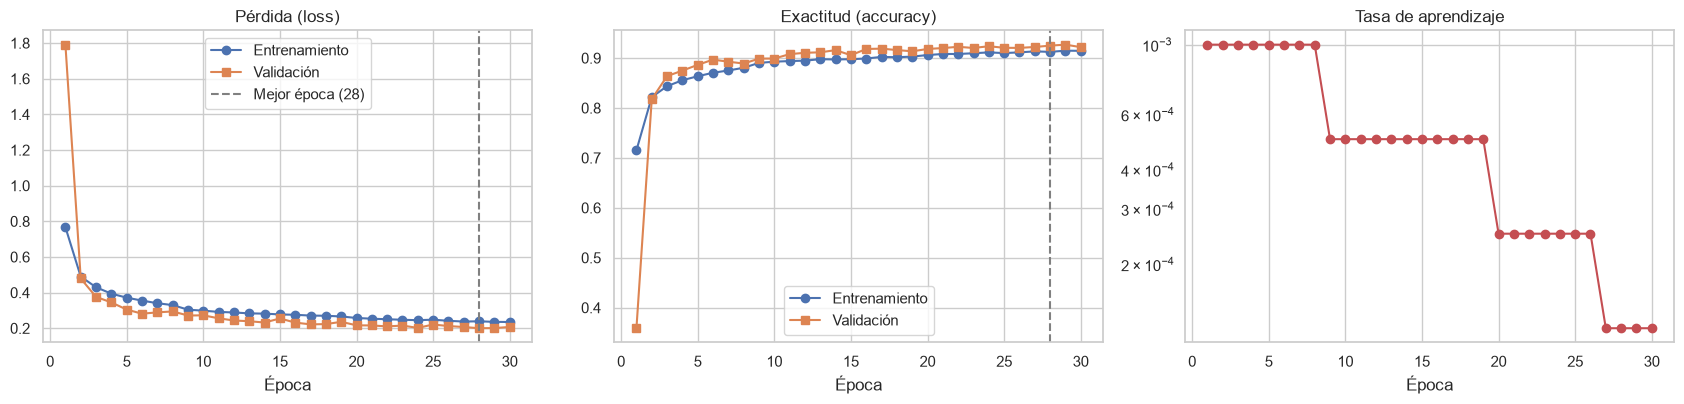

,accuracy,loss,val_accuracy,val_loss,learning_rate
Época,,,,,
23,0.9096,0.2476,0.9202,0.2149,0.0003
24,0.9113,0.2451,0.9237,0.2019,0.0003
25,0.9099,0.2480,0.9205,0.2209,0.0003
26,0.9114,0.2417,0.9203,0.2123,0.0003
27,0.9133,0.2376,0.9222,0.2068,0.0001
28,0.9124,0.2389,0.9248,0.2001,0.0001
29,0.9147,0.2358,0.9268,0.2008,0.0001
30,0.9144,0.2349,0.9218,0.2073,0.0001


In [12]:
h = history.history
epocas = range(1, len(h["loss"]) + 1)
fig, axes = plt.subplots(1, 3, figsize=(17, 4.2))

axes[0].plot(epocas, h["loss"], "o-", label="Entrenamiento")
axes[0].plot(epocas, h["val_loss"], "s-", label="Validación")
axes[0].axvline(mejor_epoca, ls="--", c="gray", label=f"Mejor época ({mejor_epoca})")
axes[0].set_title("Pérdida (loss)"); axes[0].set_xlabel("Época"); axes[0].legend()

axes[1].plot(epocas, h["accuracy"], "o-", label="Entrenamiento")
axes[1].plot(epocas, h["val_accuracy"], "s-", label="Validación")
axes[1].axvline(mejor_epoca, ls="--", c="gray")
axes[1].set_title("Exactitud (accuracy)"); axes[1].set_xlabel("Época"); axes[1].legend()

axes[2].plot(epocas, h["learning_rate"], "o-", c="#C44E52")
axes[2].set_yscale("log"); axes[2].set_title("Tasa de aprendizaje"); axes[2].set_xlabel("Época")
plt.tight_layout(); plt.show()

pd.DataFrame(h, index=pd.Index(epocas, name="Época")).round(4).tail(8)

**Lectura de las curvas:** al usar Data Augmentation y Dropout, la exactitud de entrenamiento suele ser *menor o similar* a la de validación durante las primeras épocas (el modelo ve imágenes "más difíciles" al entrenar y el Dropout está activo). Si ambas curvas avanzan juntas sin que `val_loss` se dispare, el modelo **no está sobreajustando**. Las caídas de la tasa de aprendizaje suelen coincidir con saltos de mejora en validación.

## 9. Evaluación en el conjunto de prueba

### 9.1 Métricas globales

In [13]:
test_loss, test_acc = model.evaluate(x_test_p, y_test, verbose=0)
y_prob = model.predict(x_test_p, verbose=0)
y_pred = y_prob.argmax(axis=1)

p_macro, r_macro, f1_macro, _ = precision_recall_fscore_support(y_test, y_pred, average="macro")
p_w, r_w, f1_w, _ = precision_recall_fscore_support(y_test, y_pred, average="weighted")

metricas = pd.DataFrame({
    "Métrica": ["Loss", "Accuracy", "Precision (macro)", "Recall (macro)", "F1 (macro)",
                "Precision (weighted)", "Recall (weighted)", "F1 (weighted)"],
    "Valor": [test_loss, accuracy_score(y_test, y_pred), p_macro, r_macro, f1_macro, p_w, r_w, f1_w],
})
display(metricas.style.format({"Valor": "{:.4f}"}).hide(axis="index"))

Métrica,Valor
Loss,0.2257
Accuracy,0.9148
Precision (macro),0.9180
Recall (macro),0.9148
F1 (macro),0.9157
Precision (weighted),0.9180
Recall (weighted),0.9148
F1 (weighted),0.9157


### 9.2 Reporte de clasificación por clase

                     precision    recall  f1-score   support

       Camiseta/top     0.9027    0.8070    0.8522      1000
           Pantalón     0.9969    0.9760    0.9864      1000
             Suéter     0.9179    0.8720    0.8944      1000
            Vestido     0.9171    0.9180    0.9175      1000
             Abrigo     0.8627    0.8800    0.8713      1000
           Sandalia     0.9810    0.9790    0.9800      1000
             Camisa     0.7045    0.8060    0.7519      1000
Zapatilla deportiva     0.9416    0.9680    0.9546      1000
              Bolso     0.9812    0.9910    0.9861      1000
              Botín     0.9744    0.9510    0.9626      1000

           accuracy                         0.9148     10000
          macro avg     0.9180    0.9148    0.9157     10000
       weighted avg     0.9180    0.9148    0.9157     10000



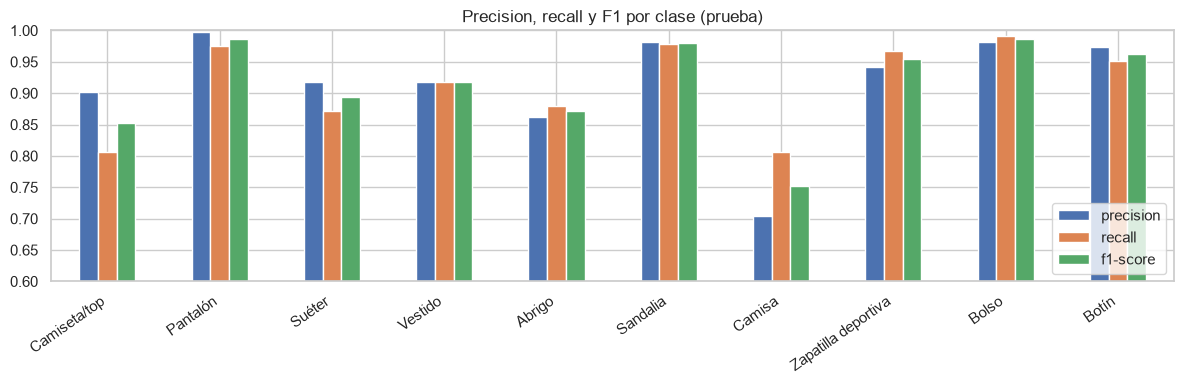

In [14]:
print(classification_report(y_test, y_pred, target_names=CLASS_NAMES, digits=4))

rep = pd.DataFrame(classification_report(y_test, y_pred, target_names=CLASS_NAMES,
                                         output_dict=True)).T.iloc[:NUM_CLASSES]
ax = rep[["precision", "recall", "f1-score"]].plot(kind="bar", figsize=(12, 4), ylim=(0.6, 1.0))
ax.set_title("Precision, recall y F1 por clase (prueba)"); ax.set_xlabel("")
plt.xticks(rotation=35, ha="right"); plt.legend(loc="lower right"); plt.tight_layout(); plt.show()

### 9.3 Matriz de confusión

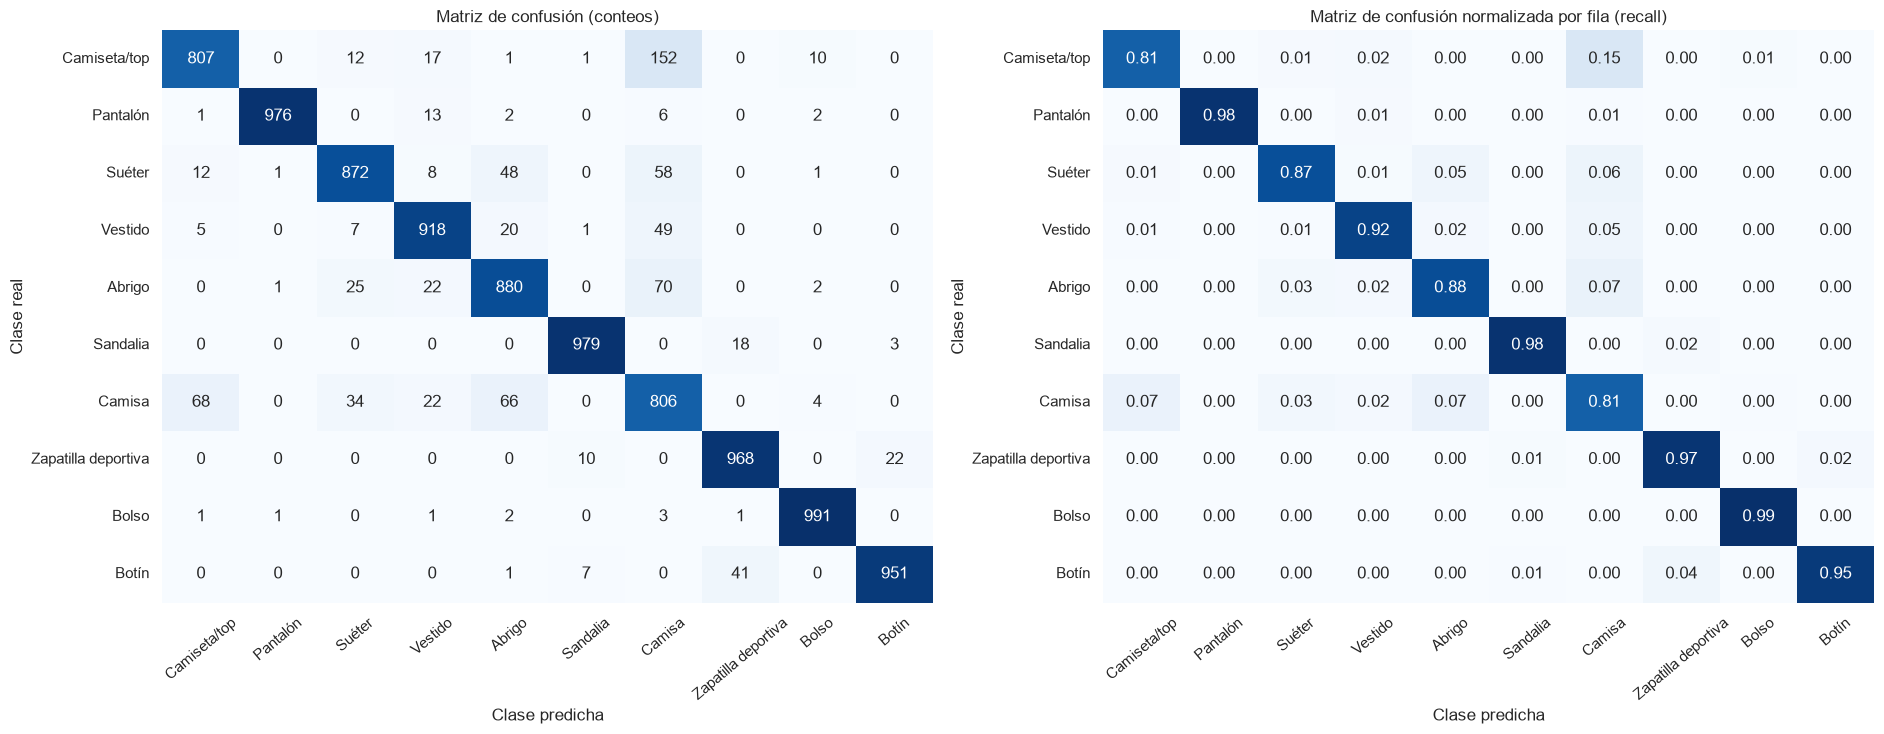

,Errores,Clase real,Predicha como
0,152,Camiseta/top,Camisa
1,70,Abrigo,Camisa
2,68,Camisa,Camiseta/top
3,66,Camisa,Abrigo
4,58,Suéter,Camisa
5,49,Vestido,Camisa


In [15]:
cm = confusion_matrix(y_test, y_pred)
cm_norm = cm / cm.sum(axis=1, keepdims=True)

fig, axes = plt.subplots(1, 2, figsize=(19, 7.5))
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", ax=axes[0],
            xticklabels=CLASS_NAMES, yticklabels=CLASS_NAMES, cbar=False)
axes[0].set_title("Matriz de confusión (conteos)")
sns.heatmap(cm_norm, annot=True, fmt=".2f", cmap="Blues", ax=axes[1],
            xticklabels=CLASS_NAMES, yticklabels=CLASS_NAMES, cbar=False)
axes[1].set_title("Matriz de confusión normalizada por fila (recall)")
for ax in axes:
    ax.set_xlabel("Clase predicha"); ax.set_ylabel("Clase real")
    ax.tick_params(axis="x", rotation=40); ax.tick_params(axis="y", rotation=0)
plt.tight_layout(); plt.show()

# Pares de clases más confundidos
cm_off = cm.copy(); np.fill_diagonal(cm_off, 0)
pares = sorted(((cm_off[i, j], CLASS_NAMES[i], CLASS_NAMES[j])
                for i in range(NUM_CLASSES) for j in range(NUM_CLASSES)), reverse=True)[:6]
display(pd.DataFrame(pares, columns=["Errores", "Clase real", "Predicha como"]))

## 10. Visualización de predicciones

### 10.1 20 predicciones aleatorias del conjunto de prueba

En verde las correctas y en rojo las incorrectas; se muestra la clase predicha, su confianza (probabilidad softmax) y la clase real.

Aciertos en esta muestra: 19/20


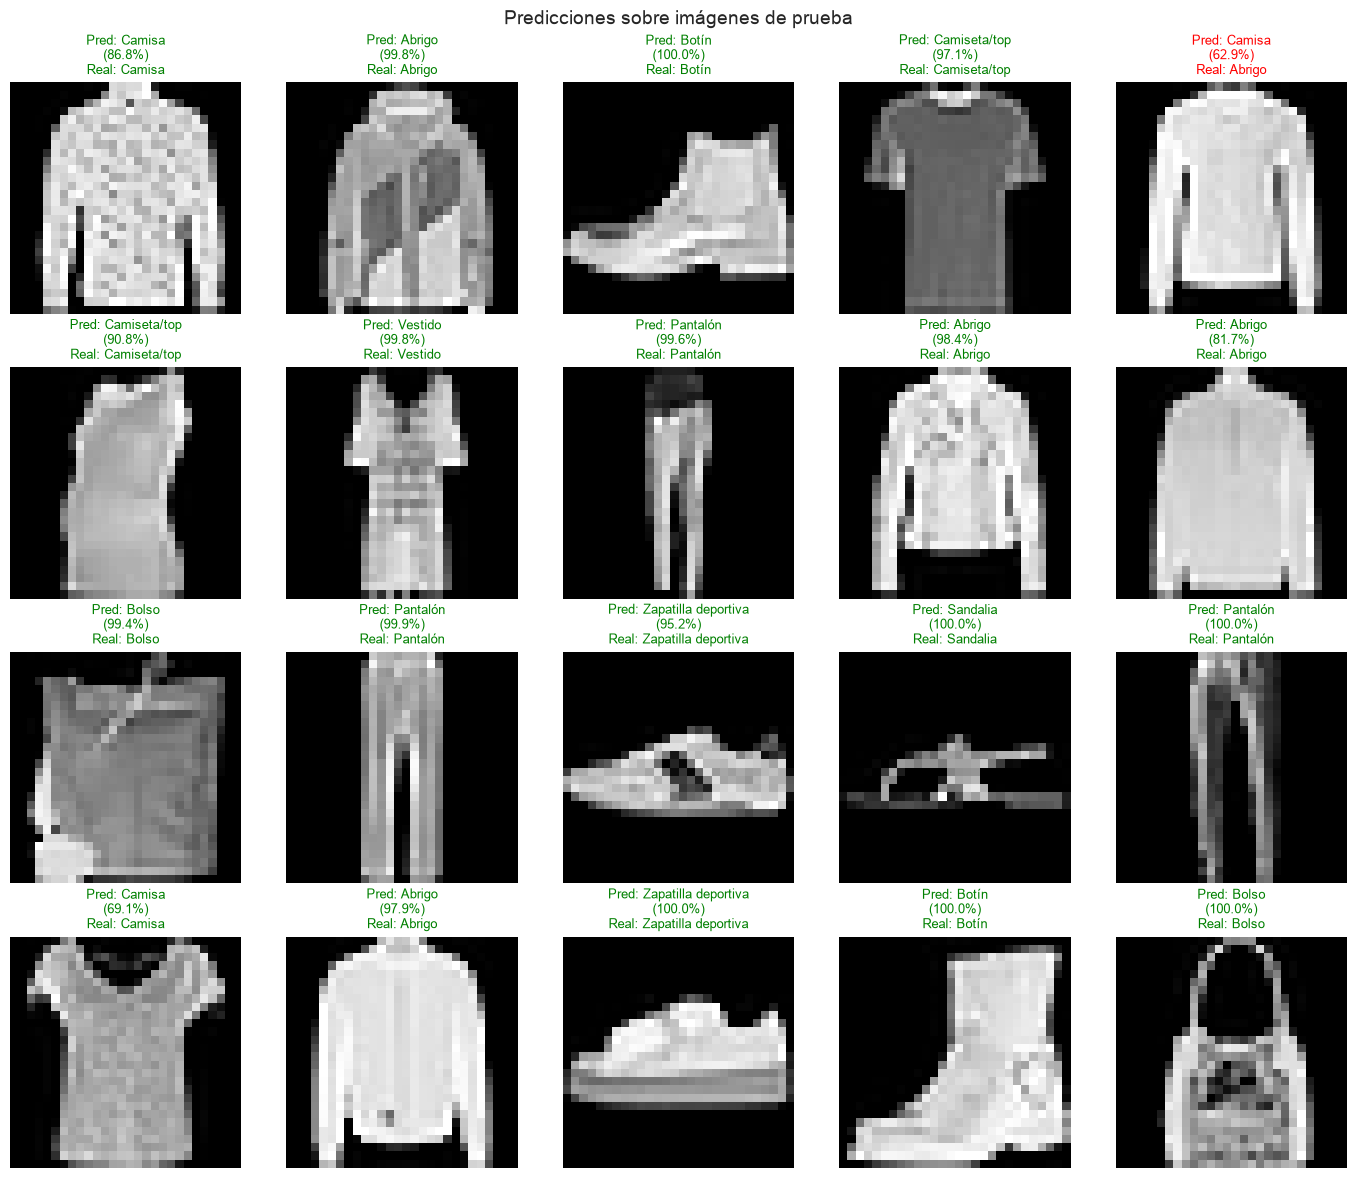

In [16]:
idx = np.random.default_rng(7).choice(len(x_test_p), 20, replace=False)
fig, axes = plt.subplots(4, 5, figsize=(14, 12))
for ax, i in zip(axes.ravel(), idx):
    ax.imshow(x_test[i], cmap="gray"); ax.axis("off")
    ok = y_pred[i] == y_test[i]
    ax.set_title(f"Pred: {CLASS_NAMES[y_pred[i]]}\n({y_prob[i].max():.1%})\nReal: {CLASS_NAMES[y_test[i]]}",
                 color="green" if ok else "red", fontsize=9)
print(f"Aciertos en esta muestra: {(y_pred[idx] == y_test[idx]).sum()}/20")
plt.suptitle("Predicciones sobre imágenes de prueba", fontsize=14); plt.tight_layout(); plt.show()

### 10.2 Predicción con distribución de probabilidades (top-3)

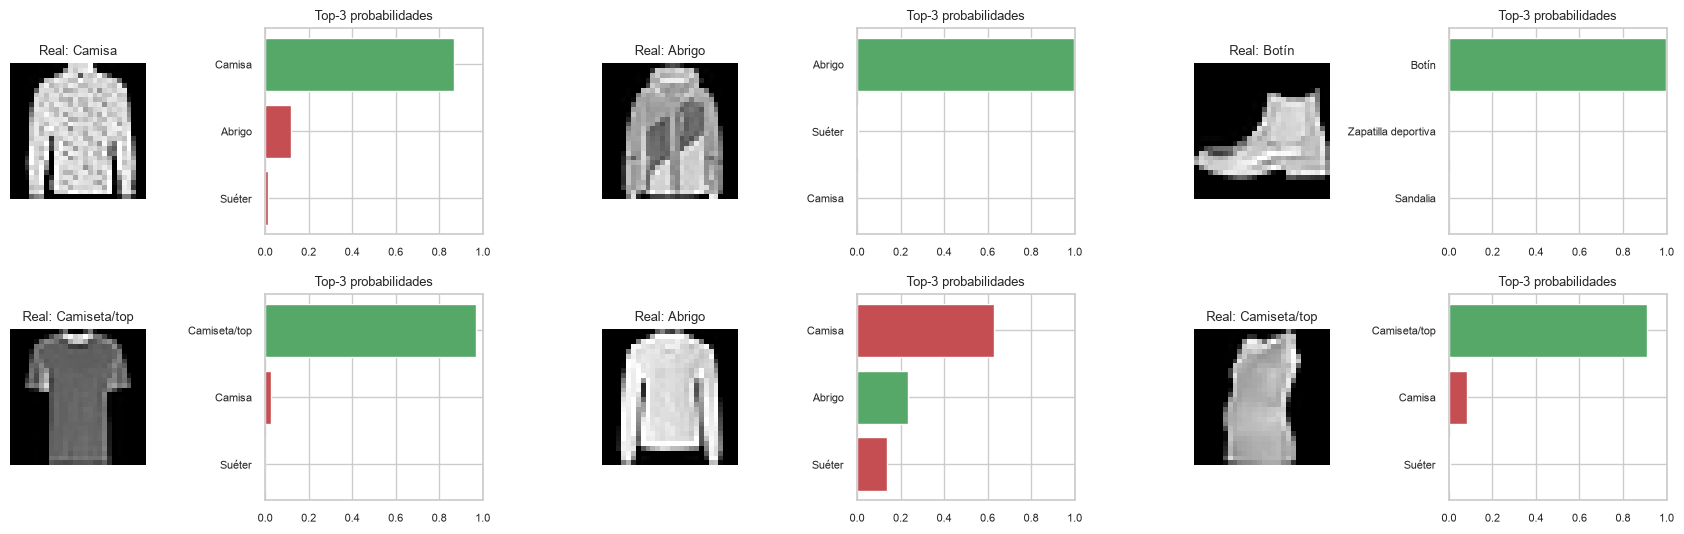

In [17]:
fig, axes = plt.subplots(2, 6, figsize=(17, 5.5), gridspec_kw={"width_ratios": [1, 1.6] * 3})
for k, i in enumerate(idx[:6]):
    a_img, a_bar = axes[k // 3, (k % 3) * 2], axes[k // 3, (k % 3) * 2 + 1]
    a_img.imshow(x_test[i], cmap="gray"); a_img.axis("off")
    a_img.set_title(f"Real: {CLASS_NAMES[y_test[i]]}", fontsize=9)
    top3 = np.argsort(y_prob[i])[::-1][:3]
    a_bar.barh([CLASS_NAMES[t] for t in top3][::-1], y_prob[i][top3][::-1],
               color=["#C44E52" if t != y_test[i] else "#55A868" for t in top3][::-1])
    a_bar.set_xlim(0, 1); a_bar.set_title("Top-3 probabilidades", fontsize=9)
    a_bar.tick_params(labelsize=8)
plt.tight_layout(); plt.show()

### 10.3 Errores con mayor confianza

Analizar los errores ayuda a entender las limitaciones del modelo.

Total de errores en prueba: 852 de 10000 (8.52%)


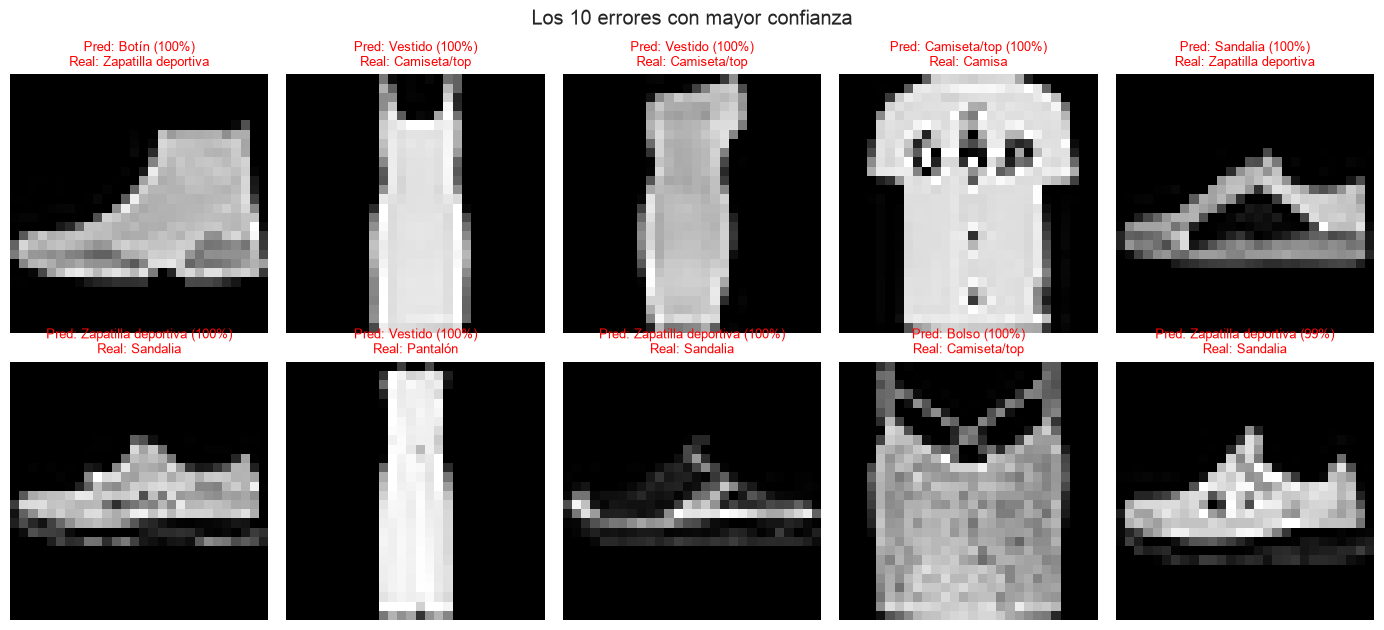

In [18]:
errores = np.where(y_pred != y_test)[0]
peores = errores[np.argsort(y_prob[errores].max(axis=1))[::-1][:10]]
fig, axes = plt.subplots(2, 5, figsize=(14, 6.5))
for ax, i in zip(axes.ravel(), peores):
    ax.imshow(x_test[i], cmap="gray"); ax.axis("off")
    ax.set_title(f"Pred: {CLASS_NAMES[y_pred[i]]} ({y_prob[i].max():.0%})\nReal: {CLASS_NAMES[y_test[i]]}",
                 color="red", fontsize=9)
print(f"Total de errores en prueba: {len(errores)} de {len(y_test)} ({len(errores)/len(y_test):.2%})")
plt.suptitle("Los 10 errores con mayor confianza"); plt.tight_layout(); plt.show()

## 11. Guardado del modelo

El modelo se guarda en formato nativo de Keras (`.keras`), que incluye arquitectura, pesos, configuración del optimizador y las capas de Data Augmentation (inactivas en inferencia). Además se guardan el historial y las métricas en `reports/`, y algunas imágenes de prueba en `samples/` para probar `src/predict.py` y la app Streamlit. Finalmente se recarga el modelo para verificar que produce las mismas predicciones.

In [19]:
from PIL import Image

ruta_modelo = MODELS_DIR / "fashion_mnist_cnn.keras"
model.save(ruta_modelo)
print("Modelo guardado en:", ruta_modelo.resolve(), f"({ruta_modelo.stat().st_size/1024:.0f} KB)")

(REPORTS_DIR / "history.json").write_text(json.dumps({k: [float(v) for v in vals] for k, vals in h.items()}, indent=2))
(REPORTS_DIR / "metrics.json").write_text(json.dumps({
    "test_loss": float(test_loss), "accuracy": float(test_acc),
    "precision_macro": float(p_macro), "recall_macro": float(r_macro), "f1_macro": float(f1_macro),
    "epocas_ejecutadas": len(h["loss"]), "mejor_epoca": mejor_epoca,
    "confusion_matrix": cm.tolist(), "class_names": CLASS_NAMES,
}, indent=2, ensure_ascii=False))

# Una imagen de prueba por clase (ampliada a 112x112) para la app y para predict.py
SAMPLES_DIR = RAIZ / "samples"; SAMPLES_DIR.mkdir(exist_ok=True)
for c in range(NUM_CLASSES):
    i = int(np.where(y_test == c)[0][0])
    nombre = CLASS_NAMES[c].lower().replace("/", "_").replace(" ", "_")
    Image.fromarray(x_test[i]).resize((112, 112), Image.NEAREST).save(SAMPLES_DIR / f"{c}_{nombre}.png")
print("Imágenes de ejemplo:", sorted(p.name for p in SAMPLES_DIR.glob("*.png")))

# Verificación: recargar el modelo y comparar predicciones
recargado = keras.models.load_model(ruta_modelo)
iguales = np.allclose(recargado.predict(x_test_p[:200], verbose=0), y_prob[:200], atol=1e-5)
print("¿El modelo recargado produce las mismas predicciones?", iguales)

Modelo guardado en: /Users/jaimecladeron/Desktop/uninpahu/cnn-streamlit/models/fashion_mnist_cnn.keras (1937 KB)
Imágenes de ejemplo: ['0_camiseta_top.png', '1_pantalón.png', '2_suéter.png', '3_vestido.png', '4_abrigo.png', '5_sandalia.png', '6_camisa.png', '7_zapatilla_deportiva.png', '8_bolso.png', '9_botín.png']


¿El modelo recargado produce las mismas predicciones? True


**Probar el modelo guardado** (desde la raíz del repositorio):

```bash
python src/predict.py samples/0_camiseta_top.png
streamlit run app.py
```

## 12. Conclusiones

1. **Desempeño global.** La CNN alcanza en el conjunto de prueba (10.000 imágenes nunca vistas) una **accuracy de 91,48 %**, con **precision macro 0,918, recall macro 0,915 y F1 macro 0,916**. Al ser un dataset balanceado, las métricas macro y ponderadas coinciden, y la accuracy es representativa del rendimiento real.

2. **Entrenamiento y regularización.** Las curvas de loss/accuracy muestran que entrenamiento y validación avanzan juntas: la exactitud de validación (≈92,5 % en la mejor época) se mantiene incluso *por encima* de la de entrenamiento (≈91,2 %), efecto esperado de la Data Augmentation y el Dropout, que solo actúan al entrenar. **No hay sobreajuste.** ReduceLROnPlateau redujo la tasa de aprendizaje en tres ocasiones (1e-3 → 5e-4 → 2,5e-4 → 1,25e-4) y cada reducción vino seguida de una nueva mejora en `val_loss`.

3. **EarlyStopping.** Se configuró con paciencia 5 y `restore_best_weights=True`. En esta ejecución `val_loss` siguió mejorando hasta la época 28 (de 30), por lo que el entrenamiento llegó al máximo de épocas y se restauraron los pesos de la mejor época (28). Esto indica que con algunas épocas más el modelo podría mejorar ligeramente; EarlyStopping protege de entrenar de más si se aumenta el límite.

4. **Análisis por clase.** *Pantalón, Bolso, Sandalia, Botín y Zapatilla deportiva* superan un F1 de 0,95 gracias a sus siluetas distintivas. La clase más difícil es **Camisa (F1 ≈ 0,75)**, seguida de *Camiseta/top* (0,85) y *Abrigo* (0,87). La matriz de confusión confirma lo anticipado en la exploración: los errores se concentran entre prendas superiores (Camiseta/top → Camisa es la confusión más frecuente, con 152 casos), que a 28×28 píxeles en escala de grises son casi indistinguibles incluso para una persona.

5. **Errores con alta confianza.** Varios de los errores con ~100 % de confianza corresponden a imágenes cuya etiqueta original es dudosa: por ejemplo, una prenda larga con tirantes etiquetada como *Pantalón* (predicha *Vestido*) o un calzado de caña alta etiquetado como *Zapatilla deportiva* (predicho *Botín*). Esto sugiere que parte del error residual se debe a ruido de etiquetado en el propio dataset y no es corregible solo mejorando el modelo.

6. **Posibles mejoras.** Entrenar más épocas (o con un *schedule* de tasa de aprendizaje tipo coseno), redes más profundas/anchas o con conexiones residuales, *test-time augmentation* o *ensembles* de varios modelos; estas técnicas suelen llevar Fashion-MNIST a 93–94 %.

7. **Despliegue.** El modelo final se guardó en `models/fashion_mnist_cnn.keras` (≈1,9 MB), se verificó que al recargarlo produce las mismas predicciones, y se utiliza desde `src/predict.py` (línea de comandos) y desde la aplicación Streamlit `app.py`, que muestra la clase predicha, su confianza y el top-3.
